<center><h1>Mutyala_Yogita_HW6</h1></center>

Name: Yogita Mutyala
<br>
Github Username: yogitamutyala
<br>
USC ID: 4421997071

## 1. Tree-Based Methods

Import packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, roc_curve, roc_auc_score
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

### (a) Download the APS Failure data

In [2]:
train_data = pd.read_csv("../data/aps_failure_training_set.csv", skiprows=20, na_values="na" )
test_data = pd.read_csv( "../data/aps_failure_test_set.csv", skiprows=20, na_values="na" )
print("Training shape is ", train_data.shape," , test shape is", test_data.shape, ", positive training rows are", (train_data["class"] == "pos").sum(),",number of features are ", train_data.shape[1] - 1,", if all features are numeric is", train_data.drop(columns="class").dtypes.apply( pd.api.types.is_numeric_dtype ).all())

Training shape is  (60000, 171)  , test shape is (16000, 171) , positive training rows are 1000 ,number of features are  170 , if all features are numeric is True


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Some usual techniques are:
1. Deleting incomplete rows
2. Replcaing missing values with mean or median
3. KNN Imputation
4. Model-based imputation
Since the dataset has missing values, deleting rows may remove too much data, so median imputation can be used beacause it is less affected by extreme values.

In [3]:
X_train = train_data.drop(columns="class")
y_train = train_data["class"].map({"neg": 0, "pos": 1})
X_test = test_data.drop(columns="class")
y_test = test_data["class"].map({"neg": 0, "pos": 1})
imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame( imputer.fit_transform(X_train), columns=X_train.columns )
X_test = pd.DataFrame( SimpleImputer(strategy="median").fit_transform(X_test), columns=X_test.columns )
print("Missing training values are", X_train.isna().sum().sum(),"and missing test values are", X_test.isna().sum().sum())

Missing training values are 0 and missing test values are 0


#### (ii) Calculate the coefficient of variation

In [4]:
# CV
cv = (X_train.std(ddof=1) / X_train.mean()).sort_values(ascending=False)
cv_table = cv.rename("CV").to_frame()
display(cv_table)

,CV
cf_000,244.887517
co_000,244.507385
ad_000,244.322816
cs_009,237.930554
dh_000,123.216097
...,...
bo_000,0.792383
bp_000,0.753392
bq_000,0.718534
br_000,0.689112


#### (iii) Plot a correlation matrix

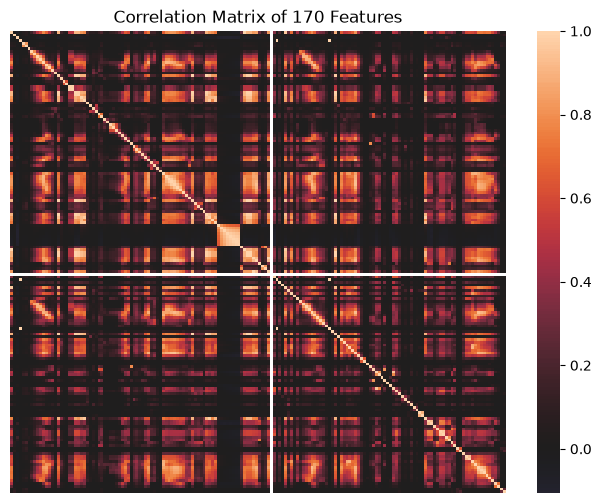

In [5]:
plt.figure(figsize=(8,6))
sns.heatmap( X_train.corr(),center=0,xticklabels=False,yticklabels=False)
plt.title("Correlation Matrix of 170 Features")
plt.show()

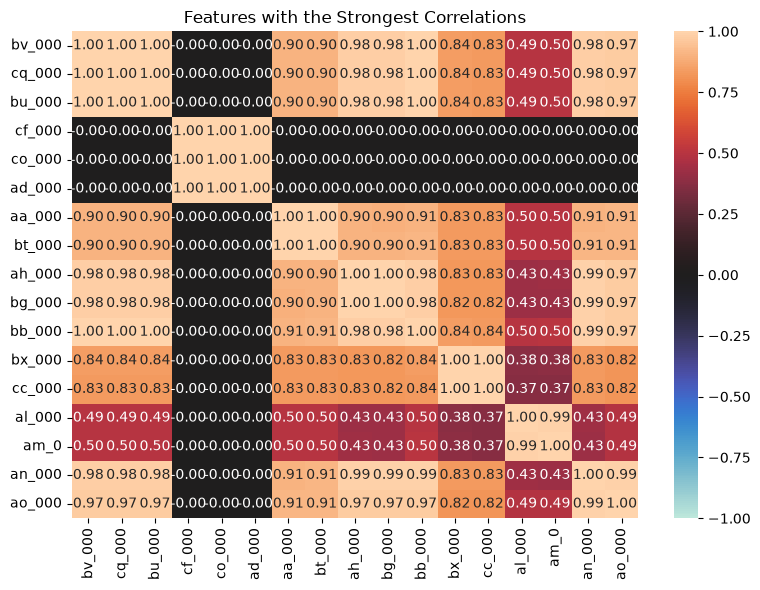

In [6]:
# improve vizualisation readability with strongest correlation
correlation = X_train.corr()
#15 strongest feature pairs
upper = correlation.abs().where(np.triu(np.ones(correlation.shape), k=1).astype(bool))
top_pairs = upper.stack().nlargest(15)
top_features = list(dict.fromkeys( feature for pair in top_pairs.index for feature in pair ))
plt.figure(figsize=(8,6))
sns.heatmap( correlation.loc[top_features, top_features], center=0, vmin=-1, vmax=1, annot=True, fmt=".2f" )
plt.title("Features with the Strongest Correlations")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

#### (iv) Make scatter plots and box plots

In [7]:
top_cv_features = cv.replace([np.inf, -np.inf], np.nan).dropna().head(13).index
print(top_cv_features.tolist())

['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


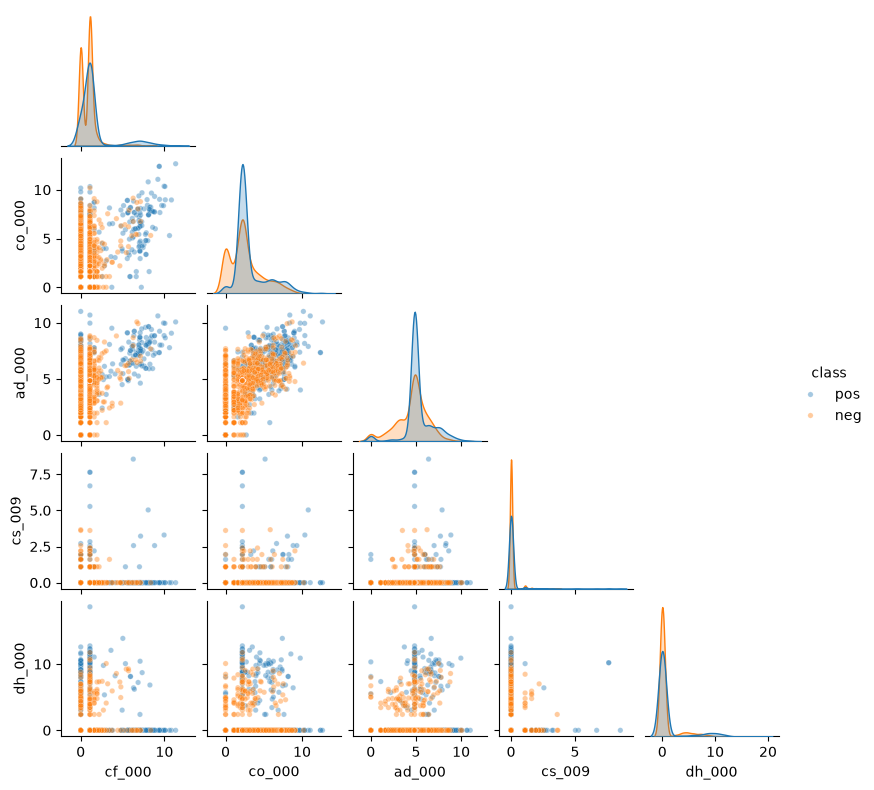

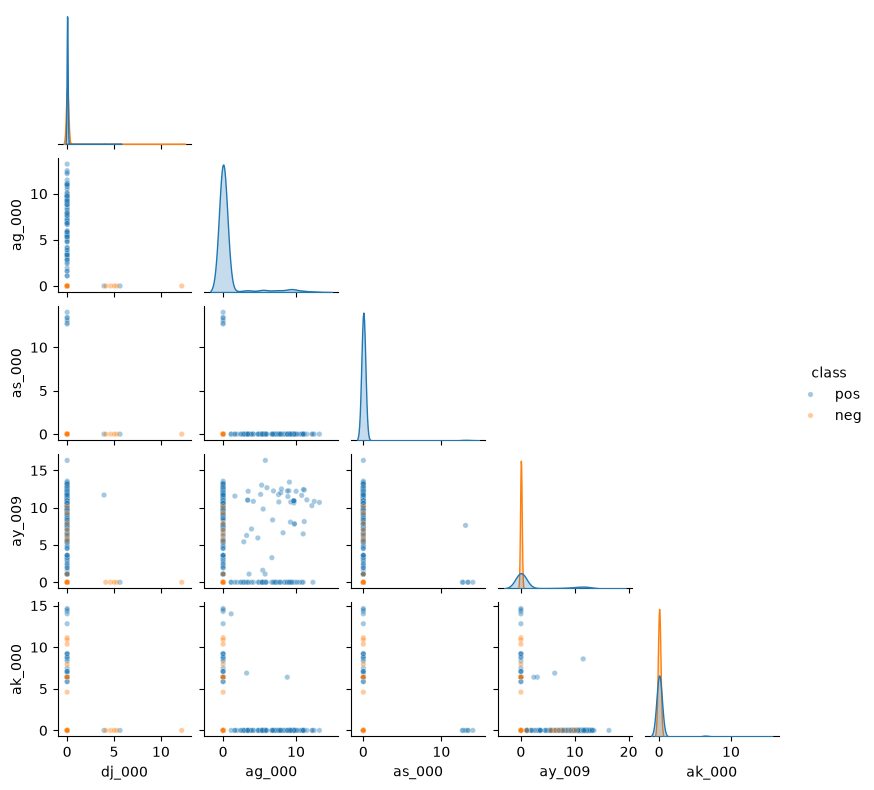

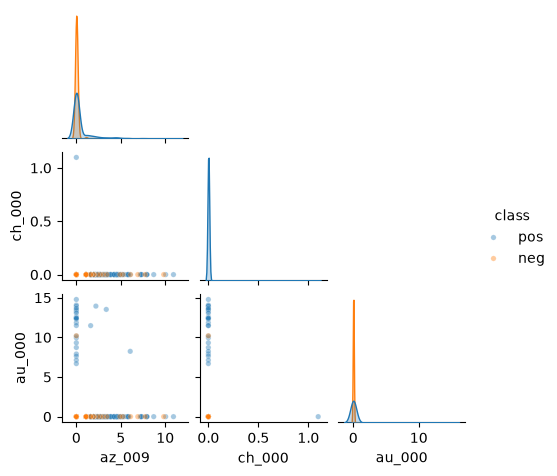

In [8]:
#scatter plot
plot_indices = pd.concat([  y_train[y_train == 1], y_train[y_train == 0].sample(1000, random_state=42) ]).index
plot_data = np.log1p(X_train.loc[plot_indices, top_cv_features])
plot_data["class"] = y_train.loc[plot_indices].map({0: "neg", 1: "pos"})
# Split features into smaller groups for better readability
for start in range(0, 13, 5):
    features = top_cv_features[start:start + 5]
    sns.pairplot( plot_data, vars=features, hue="class", corner=True, height=1.6, plot_kws={"alpha": 0.4, "s": 15} )
    plt.show()

Understanding: The classes show different patterns for some features, but they still overlap. Therefore, statistical significance cannot be determined from these plots alone.

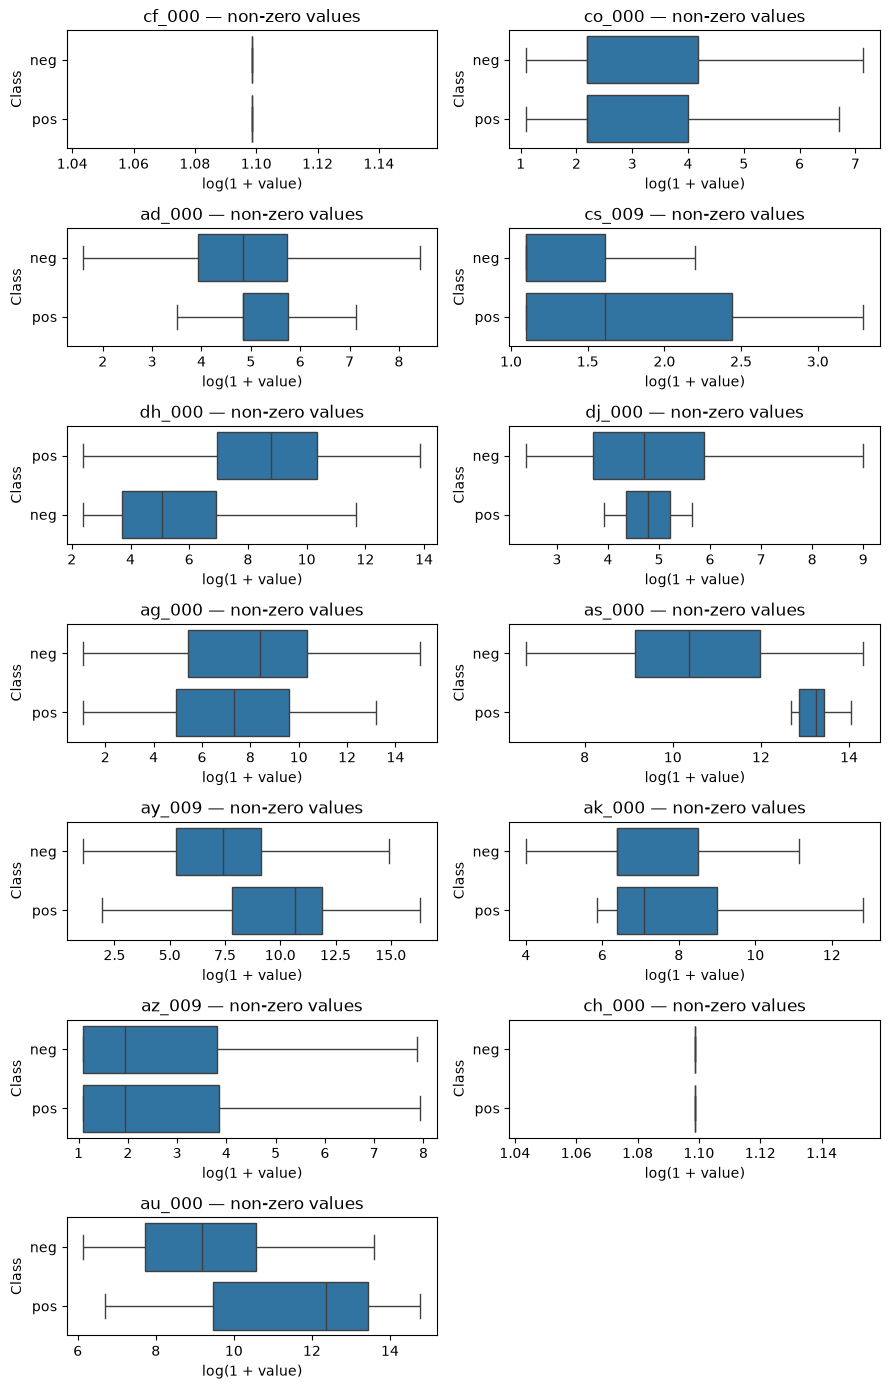

In [9]:
#box plot
fig, axes = plt.subplots(7, 2, figsize=(9,14))
class_labels = y_train.map({0: "neg", 1: "pos"})
for feature, ax in zip(top_cv_features, axes.flatten()):
    box_data = pd.DataFrame({"value": X_train[feature],"class": class_labels})
    # Show the distribution of non-zero values
    box_data = box_data[box_data["value"] > 0]
    box_data["value"] = np.log1p(box_data["value"])
    sns.boxplot( data=box_data, x="value", y="class", showfliers=False, ax=ax )
    ax.set_title(f"{feature} — non-zero values")
    ax.set_xlabel("log(1 + value)")
    ax.set_ylabel("Class")
axes.flatten()[-1].set_visible(False)
plt.tight_layout()
plt.show()

Understanding: The positive class generally has higher non-zero values for dh_000, as_000, ay_009, and au_000, so these features may help distinguish APS failures. Features such as co_000, az_009, cf_000, and ch_000 show strong overlap or almost no variation. However, box plots alone cannot establish statistical significance.

#### (v) Is this data set imbalanced?

In [10]:
class_counts = y_train.value_counts().rename(index={0: "Negative", 1: "Positive"})
print(class_counts)
print("\nPercentages:")
print((class_counts / len(y_train) * 100).round(2))

class
Negative    59000
Positive     1000
Name: count, dtype: int64

Percentages:
class
Negative    98.33
Positive     1.67
Name: count, dtype: float64


Understadning: The dataset is highly imbalanced because 98.33% of the observations are negative and only 1.67% are positive.

### (c) Train a random forest

In [11]:
rf = RandomForestClassifier( n_estimators=100, oob_score=True, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
train_pred = rf.predict(X_train)
test_pred = rf.predict(X_test)
train_prob = rf.predict_proba(X_train)[:, 1]
test_prob = rf.predict_proba(X_test)[:, 1]
train_error = 1 - accuracy_score(y_train, train_pred)
test_error = 1 - accuracy_score(y_test, test_pred)
oob_error = 1 - rf.oob_score_
print("Training confusion matrix:\n", confusion_matrix(y_train, train_pred))
print("Test confusion matrix:\n", confusion_matrix(y_test, test_pred))
print("\nTraining AUC:", roc_auc_score(y_train, train_prob))
print("Test AUC:", roc_auc_score(y_test, test_prob))
print("\nTraining misclassification:", train_error)
print("Test misclassification:", test_error)
print("OOB error:", oob_error)

Training confusion matrix:
 [[59000     0]
 [    1   999]]
Test confusion matrix:
 [[15610    15]
 [  106   269]]

Training AUC: 1.0
Test AUC: 0.9927564799999999

Training misclassification: 1.666666666666483e-05
Test misclassification: 0.0075625000000000275
OOB error: 0.006166666666666654


Understanding: The OOB error is 0.00617, which is close to the test error of 0.00756. Therefore, the OOB error provides a reasonable estimate of test performance.

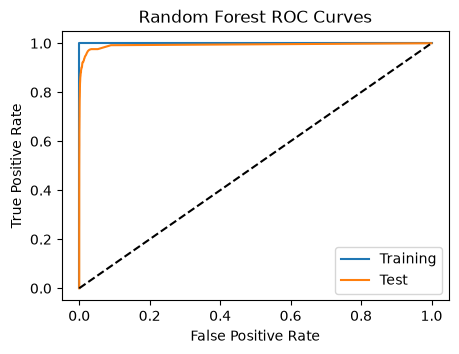

In [12]:
#ROC curved
train_fpr, train_tpr, _ = roc_curve(y_train, train_prob)
test_fpr, test_tpr, _ = roc_curve(y_test, test_prob)
plt.figure(figsize=(5, 3.5))
plt.plot(train_fpr, train_tpr, label="Training")
plt.plot(test_fpr, test_tpr, label="Test")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curves")
plt.legend()
plt.show()

### (d) Research class imbalance in random forest

Class imbalance in random forests can be addressed using class weights, undersampling the majority class, or oversampling the minority class. Here, balanced class weights are used so that mistakes on the minority positive class receive more importance.

In [23]:
rf_balanced = RandomForestClassifier( n_estimators=500, class_weight="balanced", bootstrap=True, oob_score=True, random_state=42, n_jobs=-1 )
rf_balanced.fit(X_train, y_train)
bal_train_pred = rf_balanced.predict(X_train)
bal_test_pred = rf_balanced.predict(X_test)
bal_train_prob = rf_balanced.predict_proba(X_train)[:, 1]
bal_test_prob = rf_balanced.predict_proba(X_test)[:, 1]
bal_train_error = 1 - accuracy_score(y_train, bal_train_pred)
bal_test_error = 1 - accuracy_score(y_test, bal_test_pred)
print("Training confusion matrix:\n", confusion_matrix(y_train, bal_train_pred))
print("Test confusion matrix:\n", confusion_matrix(y_test, bal_test_pred))
print("\nTraining AUC:", roc_auc_score(y_train, bal_train_prob))
print("Test AUC:", roc_auc_score(y_test, bal_test_prob))
print("\nTraining misclassification:", bal_train_error)
print("Test misclassification:", bal_test_error)

C:\Users\yogit\anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


Training confusion matrix:
 [[58990    10]
 [    0  1000]]
Test confusion matrix:
 [[15572    53]
 [   97   278]]

Training AUC: 1.0
Test AUC: 0.9943968426666667

Training misclassification: 0.0001666666666666483
Test misclassification: 0.009375000000000022


Understanding: The balanced model OOB error was not reported because valid OOB predictions were unavailable for all positive observations. Therefore, the estimate would not reliably represent both classes.

Comparison
Class weighting reduced false negatives from 106 to 97, so more positive cases were correctly detected. However, false positives increased from 15 to 53, and test error increased from 0.00756 to 0.00938. Test AUC increased slightly from 0.9928 to 0.9944.

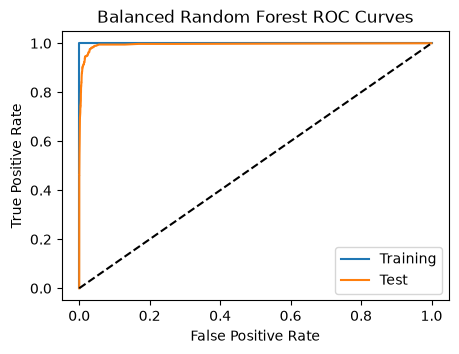

In [24]:
bal_train_fpr, bal_train_tpr, _ = roc_curve(y_train, bal_train_prob)
bal_test_fpr, bal_test_tpr, _ = roc_curve(y_test, bal_test_prob)
plt.figure(figsize=(5, 3.5))
plt.plot(bal_train_fpr, bal_train_tpr, label="Training")
plt.plot(bal_test_fpr, bal_test_tpr, label="Test")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Balanced Random Forest ROC Curves")
plt.legend()
plt.show()

### (e) XGBoost and Model Trees

In [25]:
xgb = XGBClassifier( objective="binary:logistic", eval_metric="logloss", n_estimators=100, max_depth=3, learning_rate=0.1, tree_method="hist", random_state=42, n_jobs=1 )
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
xgb_search = GridSearchCV( xgb, {"reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10, 100]}, cv=cv, scoring="accuracy", n_jobs=-1, verbose=1)
xgb_search.fit(X_train, y_train)
xgb_best = xgb_search.best_estimator_

Fitting 5 folds for each of 7 candidates, totalling 35 fits


In [26]:
#results
xgb_train_pred = xgb_best.predict(X_train)
xgb_test_pred = xgb_best.predict(X_test)
xgb_train_prob = xgb_best.predict_proba(X_train)[:, 1]
xgb_test_prob = xgb_best.predict_proba(X_test)[:, 1]
xgb_cv_error = 1 - xgb_search.best_score_
xgb_test_error = 1 - accuracy_score(y_test, xgb_test_pred)
print("Best alpha:", xgb_search.best_params_["reg_alpha"])
print("Cross-validation error:", xgb_cv_error)
print("Test error:", xgb_test_error)
print("\nTraining confusion matrix:\n", confusion_matrix(y_train, xgb_train_pred))
print("Test confusion matrix:\n", confusion_matrix(y_test, xgb_test_pred))
print("\nTraining AUC:", roc_auc_score(y_train, xgb_train_prob))
print("Test AUC:", roc_auc_score(y_test, xgb_test_prob))

Best alpha: 1
Cross-validation error: 0.007033333333333225
Test error: 0.00868749999999996

Training confusion matrix:
 [[58940    60]
 [  227   773]]
Test confusion matrix:
 [[15603    22]
 [  117   258]]

Training AUC: 0.9956567711864407
Test AUC: 0.9955455999999999


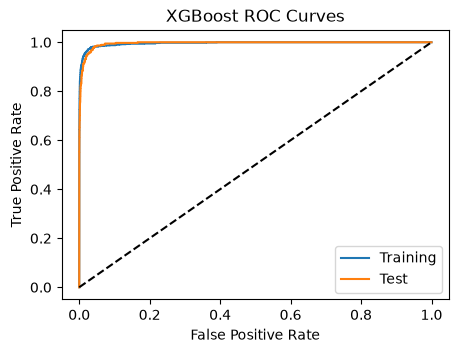

In [27]:
#roc curves
xgb_train_fpr, xgb_train_tpr, _ = roc_curve(y_train, xgb_train_prob)
xgb_test_fpr, xgb_test_tpr, _ = roc_curve(y_test, xgb_test_prob)
plt.figure(figsize=(5, 3.5))
plt.plot(xgb_train_fpr, xgb_train_tpr, label="Training")
plt.plot(xgb_test_fpr, xgb_test_tpr, label="Test")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curves")
plt.legend()
plt.show()

Understanding: Cross-validation selected alpha = 1. The cross-validation error was 0.00703, while the test error was 0.00869, so cross-validation slightly underestimated the test error. The test AUC of 0.996 indicates strong class-separation performance.

### (f) Use SMOTE to pre-process your data

In [28]:
smote_xgb = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("xgb", XGBClassifier(objective="binary:logistic",eval_metric="logloss",n_estimators=100,max_depth=3,learning_rate=0.1,tree_method="hist",random_state=42,n_jobs=1))])
smote_search = GridSearchCV(smote_xgb,{"xgb__reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10, 100]},cv=cv,scoring="accuracy",n_jobs=2,verbose=3)
smote_search.fit(X_train, y_train)
smote_best = smote_search.best_estimator_

Fitting 5 folds for each of 7 candidates, totalling 35 fits


In [29]:
#results
smote_train_pred = smote_best.predict(X_train)
smote_test_pred = smote_best.predict(X_test)
smote_train_prob = smote_best.predict_proba(X_train)[:, 1]
smote_test_prob = smote_best.predict_proba(X_test)[:, 1]
smote_cv_error = 1 - smote_search.best_score_
smote_test_error = 1 - accuracy_score(y_test, smote_test_pred)
print("Best alpha:", smote_search.best_params_["xgb__reg_alpha"])
print("Cross-validation error:", smote_cv_error)
print("Test error:", smote_test_error)
print("\nTraining confusion matrix:\n", confusion_matrix(y_train, smote_train_pred))
print("Test confusion matrix:\n", confusion_matrix(y_test, smote_test_pred))
print("\nTraining AUC:", roc_auc_score(y_train, smote_train_prob))
print("Test AUC:",roc_auc_score(y_test, smote_test_prob))

Best alpha: 0
Cross-validation error: 0.020616666666666617
Test error: 0.020312499999999956

Training confusion matrix:
 [[57923  1077]
 [   72   928]]
Test confusion matrix:
 [[15325   300]
 [   25   350]]

Training AUC: 0.9937068813559322
Test AUC: 0.9929808213333333


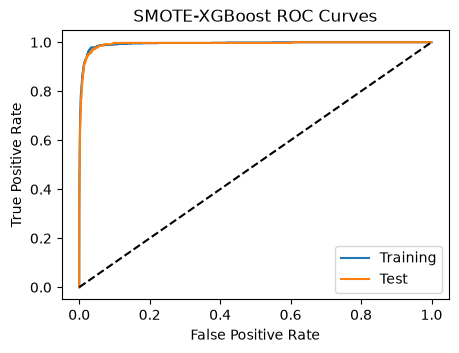

In [30]:
#roc curve
smote_train_fpr, smote_train_tpr, _ = roc_curve( y_train, smote_train_prob)
smote_test_fpr, smote_test_tpr, _ = roc_curve( y_test, smote_test_prob)
plt.figure(figsize=(5,3.5))
plt.plot(smote_train_fpr, smote_train_tpr, label="Training")
plt.plot(smote_test_fpr, smote_test_tpr, label="Test")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("SMOTE-XGBoost ROC Curves")
plt.legend()
plt.show()

Understanding: SMOTE reduced false negatives from 117 to 25, so it detected many more positive cases. However, false positives increased from 22 to 300. Test error increased from 0.00869 to 0.02031, while test AUC decreased slightly from 0.9955 to 0.9930. Therefore, SMOTE improved positive-class detection but reduced overall accuracy.

## 2. ISLR 6.6.3

As s increases, the constraint becomes less restrictive, so the model becomes more flexible.

(a) Training RSS: iv. Steadily decrease.A more flexible model fits the training data better.

(b) Test RSS: ii. Decrease initially, then eventually increase.It first improves as bias decreases, but may later overfit.

(c) Variance: iii. Steadily increase.A more flexible model is more sensitive to changes in the training data.

(d) Squared bias: iv. Steadily decrease.Increasing flexibility reduces the restrictions on the coefficients.

(e) Irreducible error: v. Remain constant.Irreducible error is caused by random noise and is unaffected by model flexibility.

## 3. ISLR 6.6.5

Since the two predictors are identical, we have:
$$
x_{11}=x_{12}, \qquad x_{21}=x_{22}
$$
Also, $\hat{\beta}_0=0$.

#### (a) The ridge regression optimization problem is:

$$
\min_{\beta_1,\beta_2}
\left[
(y_1-x_{11}(\beta_1+\beta_2))^2
+(y_2-x_{21}(\beta_1+\beta_2))^2
+\lambda(\beta_1^2+\beta_2^2)
\right]
$$

#### (b) The RSS depends only on $\beta_1+\beta_2$. For a fixed value of this sum, the ridge penalty $\beta_1^2+\beta_2^2$ is smallest when the two coefficients are equal. Therefore,

$$
\hat{\beta}_1=\hat{\beta}_2
$$

#### (c) The lasso optimization problem is:

$$
\min_{\beta_1,\beta_2}
\left[
(y_1-x_{11}(\beta_1+\beta_2))^2
+(y_2-x_{21}(\beta_1+\beta_2))^2
+\lambda(|\beta_1|+|\beta_2|)
\right]
$$

#### (d) Suppose the optimal sum is:

$$
\hat{\beta}_1+\hat{\beta}_2=c
$$

If both coefficients have the same sign, then:

$$
|\hat{\beta}_1|+|\hat{\beta}_2|=|c|
$$

Therefore, many coefficient pairs give the same RSS and the same lasso penalty. For example, 

If c>0, then any solution with $0\leq\hat{\beta}_1\leq c$ and $\hat{\beta}_2=c-\hat{\beta}_1$ has the same penalty. If c<0, the same result holds for $c\leq\hat{\beta}_1\leq0$. Therefore, the lasso coefficients are not unique.

## 4. ISLR 8.4.5

For the majority-vote approach, six of the ten estimates are greater than 0.5. Therefore, six trees predict Red and four predict Green.

The final prediction using majority vote is **Red**.

For the average-probability approach:

$$
\frac{0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75}{10}
= \frac{4.5}{10}
=0.45
$$

Since the average probability is less than 0.5, the final prediction using average probability is **Green**.

## 5. ISLR 9.7.3

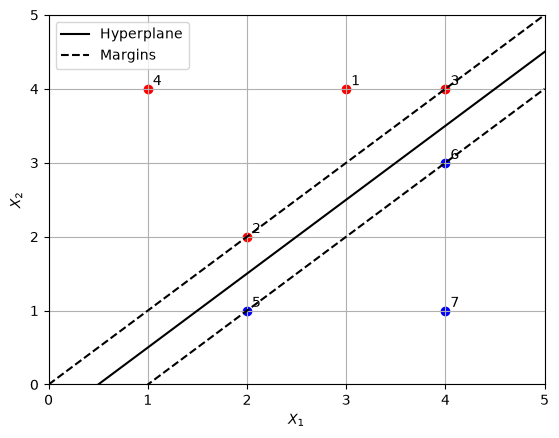

In [31]:
red = [(3,4), (2,2), (4,4), (1,4)]
blue = [(2,1), (4,3), (4,1)]
for i, (x, y) in enumerate(red + blue, 1):
    plt.scatter(x, y, color="red" if i <= 4 else "blue")
    plt.text(x + 0.05, y + 0.05, str(i))
x = [0, 5]
# a
plt.plot(x, [v - 0.5 for v in x], "k-", label="Hyperplane")
plt.plot(x, x, "k--", label="Margins")
plt.plot(x, [v - 1 for v in x], "k--")
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.xlabel("$X_1$")
plt.ylabel("$X_2$")
plt.legend()
plt.grid()
plt.show()

#### (a)–(b) The optimal separating hyperplane is: X2=X1-0.5 or equivalently, 0.5-X1+X2=0

#### (c) The classification rule is: 0.5-X_1+X_2>0 -> Red 
Otherwise, classify the observation as Blue. Therefore,

$$
\beta_0=0.5,\qquad \beta_1=-1,\qquad \beta_2=1
$$

#### (d) The two margin lines are: X2=X1 and  X2=X1-1

#### (e) The support vectors are observations 2, 3, 5, and 6: (2,2), (4,4), (2,1), (4,3)

#### (f) Observation 7, (4,1), is not a support vector. Therefore, a small movement of this observation would not change the maximal margin hyperplane.

#### (g) One non-optimal separating hyperplane is: X2=X1-0.25

It separates the classes, but it does not maximize the margin.

#### (h) Add a Blue observation at (3,3). This point lies between the Red observations (2,2) and (4,4), so the two classes can no longer be separated by a straight line.

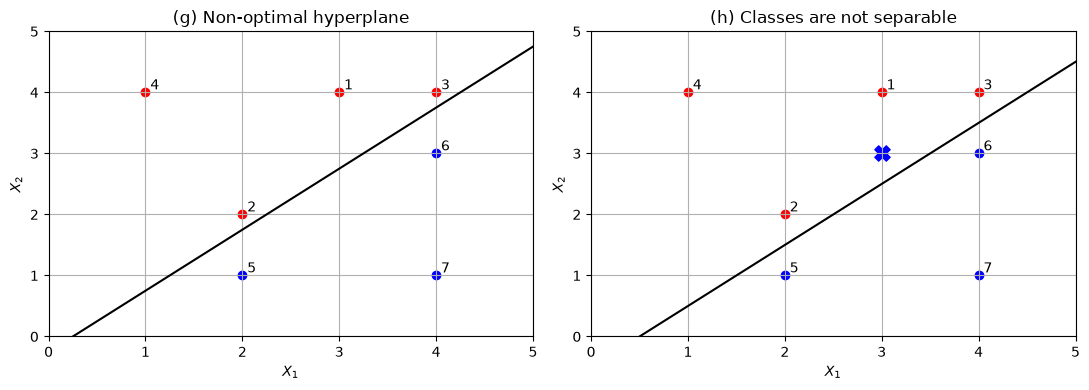

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax in axes:
    for i, (a, b) in enumerate(red + blue, 1):
        ax.scatter(a, b, color="red" if i <= 4 else "blue")
        ax.text(a + 0.05, b + 0.05, str(i))
    ax.set(xlim=(0, 5), ylim=(0, 5), xlabel="$X_1$", ylabel="$X_2$")
    ax.grid()
# (g)
axes[0].plot(x, [v - 0.25 for v in x], "k-")
axes[0].set_title("(g) Non-optimal hyperplane")
# (h)
axes[1].plot(x, [v - 0.5 for v in x], "k-")
axes[1].scatter(3, 3, color="blue", marker="X", s=120)
axes[1].set_title("(h) Classes are not separable")
plt.tight_layout()
plt.show()